Shape of data: (1797, 64)


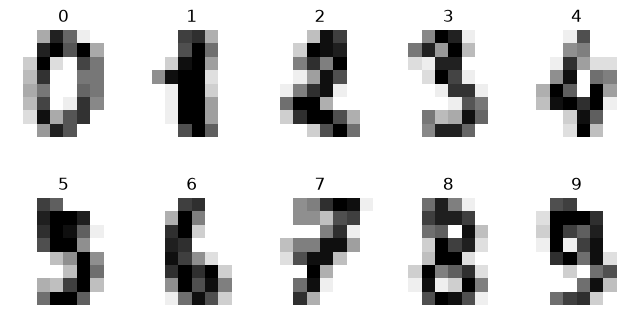

linear accuracy: 0.9778
poly accuracy: 0.9622
rbf accuracy: 0.9822
sigmoid accuracy: 0.9356

Test accuracy: 0.9822
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      1.00      1.00        37
           2       0.95      1.00      0.97        38
           3       0.98      0.96      0.97        46
           4       0.98      1.00      0.99        55
           5       0.98      1.00      0.99        59
           6       0.98      1.00      0.99        45
           7       1.00      0.95      0.97        41
           8       0.97      0.97      0.97        38
           9       0.98      0.94      0.96        48

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450



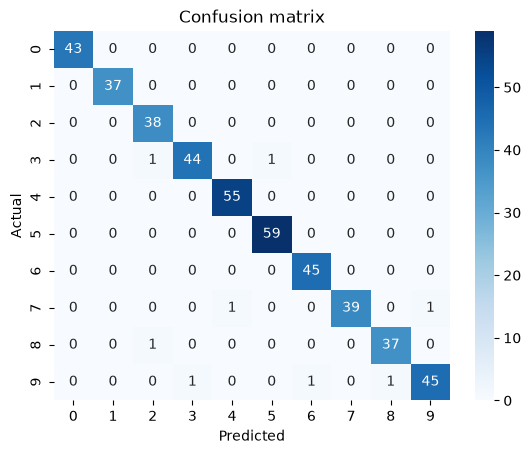

In [1]:
# Experiment 2: Classification - SVM for Handwritten Digits
# Aim: Classify images of handwritten digits (0 to 9) using Support Vector Machine.
# Dataset: Digits dataset from scikit-learn (1797 images of size 8 x 8)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

digits = load_digits()
X = digits.data
y = digits.target
print("Shape of data:", X.shape)

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(label)
    ax.axis('off')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

for k in ['linear', 'poly', 'rbf', 'sigmoid']:
    model = SVC(kernel=k)
    model.fit(X_train, y_train)
    print(k, "accuracy:", round(model.score(X_test, y_test), 4))

svm = SVC(kernel='rbf', C=10)
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

print("\nTest accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()